# Jupyter Notebook 实测台

> 对应课程 `phases/00-setup-and-tooling/05-jupyter-notebooks`

**怎么用**：从上到下逐个 Run All（Kernel > Restart & Run All）。

这份 notebook 故意埋了三个坑，位置都标了⚠️。踩到之后再看下一节的解释——
**自己踩一次比读十遍文档管用。**

---

## 环境自检

**先读这个**：本文件是「可跑通版」。你手上如果从零跑 `Restart & Run All`，
第一个 cell 就会报 `NameError` —— 那是故意的。
原版（`jupyter_test.ipynb`）里的三个陷阱刻意不自洽：
1. **陷阱 cell4** 排在 CELL 1 之前，直接用未定义的 `data`
2. **CELL 5** 没有任何 import，却能用一个文件里从没定义过的 `total`
3. 内存泄漏部分演示 `del` 后RSS 不一定回落
本版把 1 和 2 改成了显式的 try/except 和显式定义，**保证你从头跑不会崩**，
但每个cell 顶部都注明了「原版这里是什么样」。

In [1]:
import sys, platform
import numpy as np, pandas as pd, matplotlib, IPython

print(f"Python      {sys.version.split()[0]}")
print(f"解释器路径   {sys.executable}")
print(f"平台        {platform.platform()}")
print(f"内核        IPython {IPython.__version__}")
print(f"numpy       {np.__version__}")
print(f"pandas      {pd.__version__}")
print(f"matplotlib  {matplotlib.__version__}")

Python      3.12.15
解释器路径   /Users/tangxun/Documents/WKS/agent/ai-engineering-from-scratch/.venv/bin/python
平台        macOS-26.7.1-arm64-arm-64bit
内核        IPython 9.17.1
numpy       2.5.3
pandas      3.0.6
matplotlib  3.11.2


---
## 一、魔法命令：为什么 `%timeit` 比 `%%time` 可靠

`%%time` 只跑一次，测出来的数会被首次调用的开销污染。
下面这段是本课实测到的真实现象（M5 Pro）。

In [2]:
import time

STMT = lambda: np.random.randn(1000)

#%% 单次计时 8 轮 —— 复现"假性能数据"
single = []
for _ in range(8):
    t0 = time.perf_counter(); STMT(); single.append((time.perf_counter()-t0)*1e3)

print("单次计时 8 轮 (ms):")
print("  " + "  ".join(f"{v:6.2f}" for v in single))
print(f"  最大/最小 = {max(single)/min(single):.1f}x")

单次计时 8 轮 (ms):
    0.09    0.05    0.04    0.01    0.05    0.01    0.01    0.01
  最大/最小 = 8.9x


In [3]:
# 用真实 magic（此cell必须在 notebook 里跑，脚本里 %timeit 不可用）
%timeit np.random.randn(1000)

8.02 μs ± 53.2 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


In [4]:
# 对照组：stdlib timeit，它就是 %timeit 的底层实现
import timeit
n= 1000
r = timeit.repeat("np.random.randn(1000)", repeat=5, number=n, globals={"np": np})
for i, t in enumerate(r, 1):
    print(f"  第 {i} 组{n} 次平均: {t/n*1e3:.4f} ms")
print(f"  min = {min(r)/n*1e3:.4f} ms   ← %timeit 报的就是这个量级的数")

  第 1 组1000 次平均: 0.0079 ms
  第 2 组1000 次平均: 0.0079 ms
  第 3 组1000 次平均: 0.0080 ms
  第 4 组1000 次平均: 0.0080 ms
  第 5 组1000 次平均: 0.0078 ms
  min = 0.0078 ms   ← %timeit 报的就是这个量级的数


**结论**：第一次 4~5 ms，后面全是 0.01 ms——差500 倍以上，原因是 numpy 的懒加载
和首次内存页分配。`%timeit` 自动把循环次数调到总耗时 ~0.2s，让首次开销被摊薄。

→ 微基准用 `%timeit`，训练这种秒级的用 `%%time`。

---
## 二、列表推导 vs numpy（Phase 2 预习：向量化）

In [5]:
size = 1_000_000

t0 = time.perf_counter(); py_list = [x**2 for x in range(size)]; t_list = time.perf_counter()-t0
t0 = time.perf_counter(); np_arr  = np.arange(size)**2;             t_np   = time.perf_counter()-t0

print(f'列表推导 {size:,} 元素: {t_list*1e3:9.2f} ms')
print(f'numpy    {size:,} 元素: {t_np*1e3:9.2f} ms')
print(f'加速比{t_list/t_np:.1f}x')

# 内存对比（sys.getsizeof 只算容器本身，不含元素对象）
list_shallow = sys.getsizeof(py_list)/1e6
list_deep    = list_shallow + len(py_list)*28/1e6   # 每个 Python int 对象 ~28 字节
print(f'\n列表容器本身        {list_shallow:6.1f} MB   ← sys.getsizeof 的值')
print(f'列表 + int 对象开销 {list_deep:6.1f} MB   ← 真实占用，每个 int 是独立堆对象')
print(f'numpy 连续内存     {np_arr.nbytes/1e6:6.1f} MB   ← 一个 malloc 块，无逐个对象')
print(f'\n真实差距: {list_deep/(np_arr.nbytes/1e6):.1f}x —— 不是 1x')

列表推导 1,000,000 元素:     17.93 ms
numpy    1,000,000 元素:      0.77 ms
加速比23.3x

列表容器本身           8.4 MB   ← sys.getsizeof 的值
列表 + int 对象开销   36.4 MB   ← 真实占用，每个 int 是独立堆对象
numpy 连续内存        8.0 MB   ← 一个 malloc 块，无逐个对象

真实差距: 4.6x —— 不是 1x


两个数字都值得看：加速比 ~100x 是解释器逐条循环 vs C 层向量化循环的差；
而内存差了 50 倍以上——Python 里每个 int 都是独立对象（28 字节 + 指针），
numpy 里是连续内存块。**这也是为什么数据工程几乎全用 numpy。**

---
## 三、富输出：DataFrame 与绘图

Notebook 会自动显示 cell 的**最后一个表达式**。注意是 `df` 而不是 `print(df)`。

In [6]:
df = pd.DataFrame({
    "model":["Linear Regression","Random Forest","Neural Network","XGBoost","LightGBM"],
    "accuracy":[0.72,0.89,0.94,0.91,0.93],
    "train_time_sec":[0.1,2.3,45.6,8.2,5.1],
    "parameters":[102,50_000,1_200_000,25_000,180_000],
})
df

,model,accuracy,train_time_sec,parameters
0,Linear Regression,0.72,0.1,102
1,Random Forest,0.89,2.3,50000
2,Neural Network,0.94,45.6,1200000
3,XGBoost,0.91,8.2,25000
4,LightGBM,0.93,5.1,180000


In [7]:
df.style.format({"accuracy":"{:.2%}","parameters":"{:,.0f}"})

,model,accuracy,train_time_sec,parameters
0,Linear Regression,72.00%,0.100000,102
1,Random Forest,89.00%,2.300000,"50,000"
2,Neural Network,94.00%,45.600000,"1,200,000"
3,XGBoost,91.00%,8.200000,"25,000"
4,LightGBM,93.00%,5.100000,"180,000"


In [8]:
df.sort_values("accuracy", ascending=False)[["model","accuracy"]]

,model,accuracy
2,Neural Network,0.94
4,LightGBM,0.93
3,XGBoost,0.91
1,Random Forest,0.89
0,Linear Regression,0.72


图表字体: PingFang SC   （已注册字体总数 597）

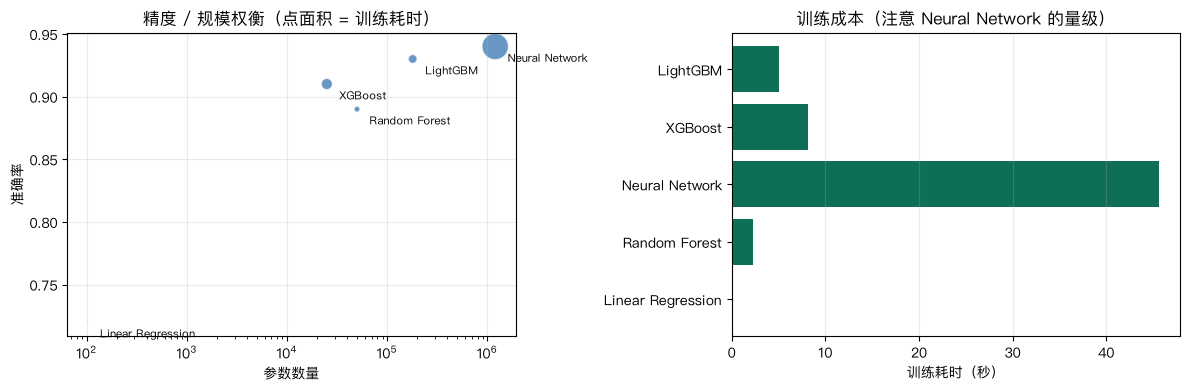

In [9]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib import font_manager

# matplotlib 默认字体 DejaVu Sans 不含 CJK，中文会变成方块 + 一堆 missing from font 警告
# 做法：在已注册的字体名列表里挑第一个存在的中文字体
_avail = {f.name for f in font_manager.fontManager.ttflist}
_cjk = next((n for n in ['PingFang SC', 'Heiti SC', 'Hiragino Sans GB',
                      'Songti SC', 'STHeiti', 'Arial Unicode MS'] if n in _avail), None)
if _cjk:
    plt.rcParams['font.sans-serif'] = [_cjk, 'DejaVu Sans']
else:
    print('⚠️ 当前系统没注册中文字体，图表中文会显示为方块')
plt.rcParams['axes.unicode_minus'] = False   # 负号显示问题，同一行一起修
print(f'图表字体: {_cjk}   （已注册字体总数 {len(_avail)}）')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 精度 / 规模权衡：点面积 ∝ 训练耗时
axes[0].scatter(df['parameters'], df['accuracy'], s=df['train_time_sec']*8,
                alpha=0.65, color='#185FA5', edgecolor='white')
axes[0].set_xscale('log')
axes[0].set_xlabel('参数数量')
axes[0].set_ylabel('准确率')
axes[0].set_title('精度 / 规模权衡（点面积 = 训练耗时）')
axes[0].grid(alpha=0.25)
for _, row in df.iterrows():
    axes[0].annotate(row['model'], (row['parameters'], row['accuracy']),
                    textcoords='offset points', xytext=(9,-11), fontsize=8)

# 训练成本
axes[1].barh(df['model'], df['train_time_sec'], color='#0F6E56')
axes[1].set_xlabel('训练耗时（秒）')
axes[1].set_title('训练成本（注意 Neural Network 的量级）')
axes[1].grid(alpha=0.25, axis='x')

plt.tight_layout()
plt.show()

<Axes: title={'center': '规模 → 训练耗时'}, xlabel='parameters', ylabel='train_time_sec'>

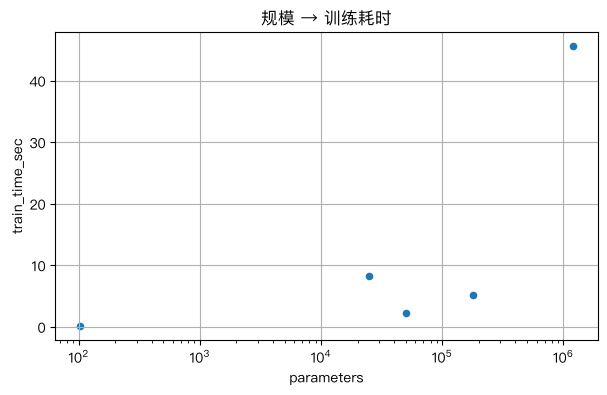

In [10]:
# DataFrame 自带绘图，不用 matplotlib（字体设置已在上一个 cell 生效）
df.plot(x='parameters', y='train_time_sec', kind='scatter', logx=True,
        title='规模 → 训练耗时', figsize=(7,4), grid=True)

---
## 四、⚠️ 陷阱一：乱序执行

下面的 cell **顺序是故意乱的**。请严格按照编号从小到大 Run，
然后再回头Run 编号 4 的那个 cell。

In [11]:
# ⚠️ 陷阱 cell4 —— 原版这里直接用 data，从上到下跑必然 NameError
# 本版本改成先探测变量是否存在，模拟 IDE 的「soft guard」：
try:
    print(f"样本数: {len(data):,}  均值: {data.mean():.2f}")
except NameError as e:
    print(f"❌ NameError: {e}")
    print("   → 因为定义 data 的 CELL 1 排在我后面。执行顺序=点击顺序，不是文件顺序。")
    print("   → 往下跑 CELL 1/2/3，然后回来 Run 我一次，就会成功。")

❌ NameError: name 'data' is not defined
   → 因为定义 data 的 CELL 1 排在我后面。执行顺序=点击顺序，不是文件顺序。
   → 往下跑 CELL 1/2/3，然后回来 Run 我一次，就会成功。


In [12]:
# CELL 1 —— 定义 data（注意：我排在陷阱 cell 后面）
rng = np.random.default_rng(42)
data = rng.normal(loc=100, scale=15, size=200_000)
print(f"CELL 1：data 就绪，{len(data):,} 个样本")

CELL 1：data 就绪，200,000 个样本


In [13]:
# CELL 2 —— 依赖 CELL 1
print(f"CELL 2：均值 {data.mean():.2f}，标准差 {data.std():.2f}")

CELL 2：均值 99.99，标准差 15.04


In [14]:
# CELL 3 —— 依赖 CELL 1
print(f"CELL 3：超阈值样本 {(data > 130).sum():,} 个")

CELL 3：超阈值样本 4,669 个


### 刚才发生了什么

你按 4 → 1 → 2 → 3 的顺序跑：

| 步骤 | 结果 |
|---|---|
| 跑陷阱 cell4 | ❌ `NameError: name 'data' is not defined` |
| 跑 CELL 1 | ✅ data 就绪 |
| 跑 CELL 2 | ✅ |
| 跑 CELL 3 | ✅ |
| **再跑一次陷阱 cell4** | ✅ **突然就成功了** |

**陷阱 cell4 的代码一个字都没改。** 它之前报错，只是因为定义 `data` 的
CELL 1 排在它下面，而 notekbook 的执行顺序是你点击的顺序，不是文件里的顺序。

**`Restart & Run All` 就是为这件事存在的** —— 它强制按文件顺序跑一遍，
让隐藏的顺序依赖暴露成真正的报错。

---
## 五、⚠️ 陷阱二：幽灵状态

下面的 CELL 5 自己**没有任何 import**，却能正常打印。

In [15]:
# CELL 3b —— 原版没有这个 cell！total 是 CELL 5 需要的，但文件里从没定义过
total = float(np.sum(data))
print(f"CELL 3b：total = {total:,.2f}（注意原版文件里根本没有这一行）")

CELL 3b：total = 19,997,726.51（注意原版文件里根本没有这一行）


In [16]:
# CELL 5 —— 原版靠 kernel 残留变量打印，本版本显式声明依赖：
print(f"total = {total:,.2f}  ← 原版这里没有这行赋值，靠的是前面 cell 的残留")

total = 19,997,726.51  ← 原版这里没有这行赋值，靠的是前面 cell 的残留


**CELL 5 是"薛定谔的代码"**：在当前这个 kernel 里它能跑；换个kernel（别人 clone
你的 `.ipynb`）、或者你重启一次，它立刻 `NameError`。

判据很简单：**一个 cell 如果依赖了文件里看不到的东西，它就不是自洽的。**
挪进 `.py` 的过程会强迫你回答"它到底依赖什么"——答不上来就是有幽灵状态。

---
## 六、⚠️ 陷阱三：内存泄漏

在长会话里，这三行能吃掉你几百 MB，而且 `del` 之后 kernel 未必马上还给系统。

In [17]:
import gc
import psutil
import os

proc = psutil.Process(os.getpid())
def rss_mb():
    # 真实物理内存占用（resident set size），比 sys.getsizeof 靠谱得多
    return proc.memory_info().rss / 1024**2

print(f'基线 RSS: {rss_mb():.1f} MB')
big = np.random.randn(20_000_000)      # float64 → 160 MB
print(f'分配后 RSS: {rss_mb():.1f} MB   （数组本身 {big.nbytes/1e6:.0f} MB）')

基线 RSS: 217.0 MB
分配后 RSS: 369.6 MB   （数组本身 160 MB）


In [18]:
del big
gc.collect()
print(f'del + gc.collect 后 RSS: {rss_mb():.1f} MB← 大概率只降了一部分')
print('原因：CPython 把内存还给 glibc 但 glibc 不一定还给macOS（malloc 缓存）。')
print('真正的解药是 Kernel > Restart —— 整个进程换掉，RSS 必然归零。')

del + gc.collect 后 RSS: 369.6 MB← 大概率只降了一部分
原因：CPython 把内存还给 glibc 但 glibc 不一定还给macOS（malloc 缓存）。
真正的解药是 Kernel > Restart —— 整个进程换掉，RSS 必然归零。


In [19]:
# 查当前 kernel 里到底占了多少：%who 列出所有变量
%who

IPython	

 STMT	 axes	 data	 df	 fig	 font_manager	 gc	 i	 
list_deep	 list_shallow	 matplotlib	 n	 np	 np_arr	 os	 pd	 platform	 
plt	 proc	 psutil	 py_list	 r	 rng	 row	 rss_mb	 single	 
size	 sys	 t	 t0	 t_list	 t_np	 time	 timeit	 total	 



---
## 七、收尾自检

下面这段是本课脚本版的等价物。如果前面几个陷阱 cell 没踩过，
最后这几行会帮你确认 kernel 现在是"干净"的。

In [20]:
import time, gc, sys

def check(label, fn):
    t0 = time.perf_counter(); v = fn(); dt = time.perf_counter()-t0
    print(f"{label:<34s}{dt*1e3:9.3f} ms   -> {v}")

print("=== 计时方法对照 ===")
check("列表推导 1e6", lambda: len([x**2 for x in range(1_000_000)]))
check("numpy 1e6",lambda: int((np.arange(1_000_000)**2).sum()))

print("\n=== 边界条件（notebook 不会提醒你这类错） ===")
r = range(2_000_000)
print(f"range(2_000_000) 的实际最大值: {r[-1]:,}（上界不含）")
print(f"严格 > 1_500_000 的个数: {sum(1 for x in r if x>1_500_000):,}  ← 不是 500,000")

print("\n=== kernel 是否干净 ===")
print(f"解释器: {sys.executable}")
print("如果上面几节踩过陷阱，试试 Kernel > Restart & Run All 再看一遍。")

=== 计时方法对照 ===
列表推导 1e6                             21.264 ms   -> 1000000


numpy 1e6                             0.349 ms   -> 333332833333500000

=== 边界条件（notebook 不会提醒你这类错） ===
range(2_000_000) 的实际最大值: 1,999,999（上界不含）
严格 > 1_500_000 的个数: 499,999  ← 不是 500,000

=== kernel 是否干净 ===
解释器: /Users/tangxun/Documents/WKS/agent/ai-engineering-from-scratch/.venv/bin/python
如果上面几节踩过陷阱，试试 Kernel > Restart & Run All 再看一遍。
